# MLB batted balls — EDA, home-run & triple classifiers, negative controls

Reproduces the exit-velocity / launch-angle geometry from the reference blog
([Tyler James Burch hit classifier](https://tylerjamesburch.com/blog/baseball/hit-classifier-3)),
then trains XGBoost models on the **2023** season (the primary dataset) to predict two
rare minority classes: **home runs** and the rarer, harder **triples**.

Two evaluation regimes are compared:

- **random** — a stratified holdout *within* 2023 (the optimistic baseline);
- **hard** — train on all of 2023, test on all of **2024** (cross-season distribution shift).

Finally, a per-feature **negative control** — a "model" that is just one feature's
correlation with the label — shows how far a single feature gets you versus the full model.

The plotting helpers live in `negative_ml.viz`, so this notebook and the scripts
(`scripts/baseball_eda_model.py`, `scripts/baseball_downselection.py`) draw the same figures.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from negative_ml.baseball import io as baseball
from negative_ml.baseball import viz
from negative_ml.core import eval as ev
from negative_ml.core.experiment import cross_dataset_split, split_from_dataset
from negative_ml.core.negative_control import run_negative_control
from negative_ml.core.splitting import random_split
from negative_ml.models import make_model
from negative_ml.viz import selection_results as rviz

# 2023 is the primary season (cached under data/raw after the first pull).
ds = baseball.load_season(2023, target="home_run")
n_pos = int(ds.y.sum())
print(
    f"{ds.n_samples:,} batted balls; {n_pos:,} home runs ({ds.y.mean():.2%} minority)"
)
ds.meta["outcome"].value_counts()

123,820 batted balls; 5,832 home runs (4.71% minority)


outcome
out         83102
single      25953
double       8223
home_run     5832
triple        710
Name: count, dtype: int64

## 1. Class balance

Most batted balls are outs; home runs are a small minority and **triples are rarer still** (~0.6%) — the imbalance this project studies.

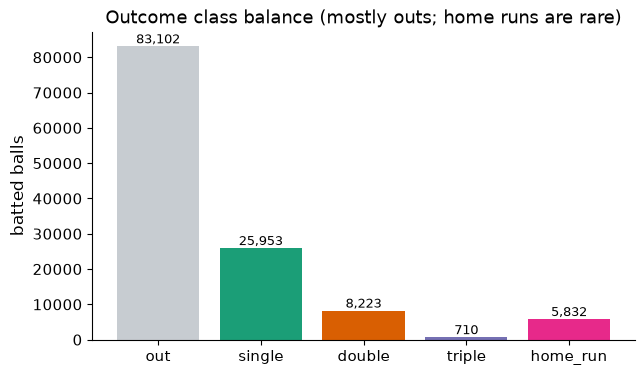

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
viz.plot_class_balance(ds.meta, ax)
plt.show()

## 2. Batted-ball geometry (reproduce the blog)

In the exit-velocity / launch-angle plane the outcome classes separate cleanly:
home runs occupy a tight high-exit-velocity, mid-launch-angle cluster (~95+ mph,
~12-50 deg). Triples, by contrast, are geometrically diffuse. The adjusted spray
angle is pull-positive and shows the expected pull skew.

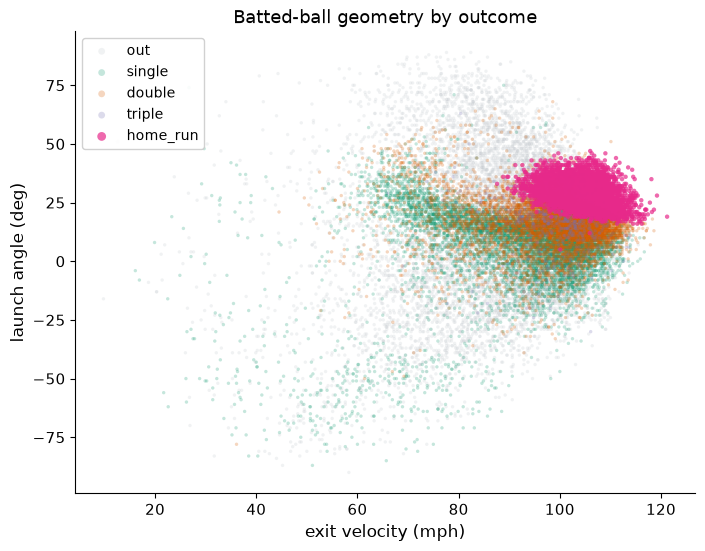

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
viz.plot_exit_velo_launch_angle(ds, ax)
plt.show()

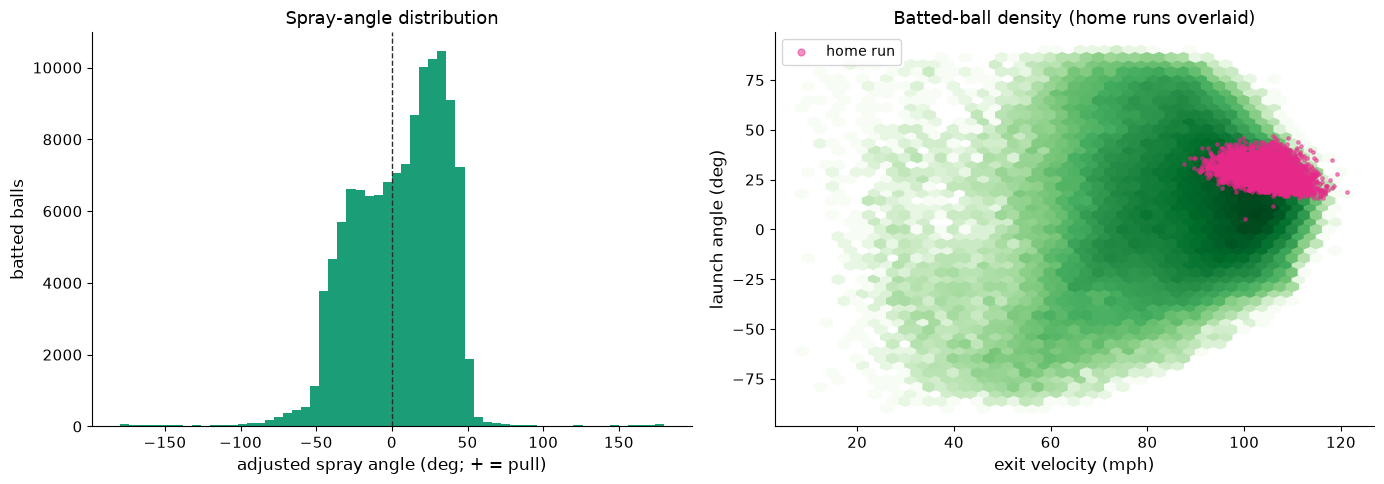

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
viz.plot_spray_distribution(ds, axes[0])
viz.plot_minority_density(ds, axes[1], label="home run")
plt.tight_layout()
plt.show()

## 3. Train an XGBoost home-run classifier (random split within 2023)

Stratified random split, then fit on the **entire** training partition — no
selection strategies yet. This confirms the data + model pipeline work end to end
before any downselection experiments.

In [5]:
train_idx, test_idx = random_split(ds, test_size=0.2)
model = make_model("classification")
model.fit(ds.X[train_idx], ds.y[train_idx])

y_test = ds.y[test_idx]
y_score = model.predict_proba(ds.X[test_idx])[:, 1]
ev.compute_metrics(y_test, y_score)

{'auroc': 0.9924373624127519,
 'auprc': 0.8708068618224172,
 'f1': 0.7846020761245674,
 'precision_at_k': 1.0,
 'enrichment_factor': 21.23842195540309}

## 4. Home-run model performance

Home runs are nearly linearly separable in this feature space, so global
discrimination is very strong (AUROC ~0.99). The predicted-probability heatmap
lights up the same region as the home-run cluster above.

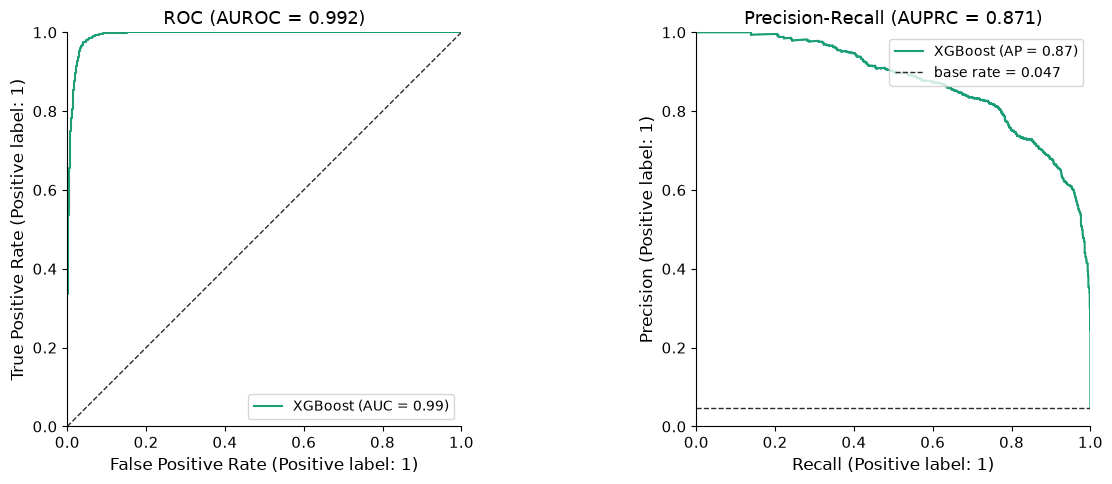

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
viz.plot_roc(y_test, y_score, axes[0])
viz.plot_pr(y_test, y_score, axes[1])
plt.tight_layout()
plt.show()

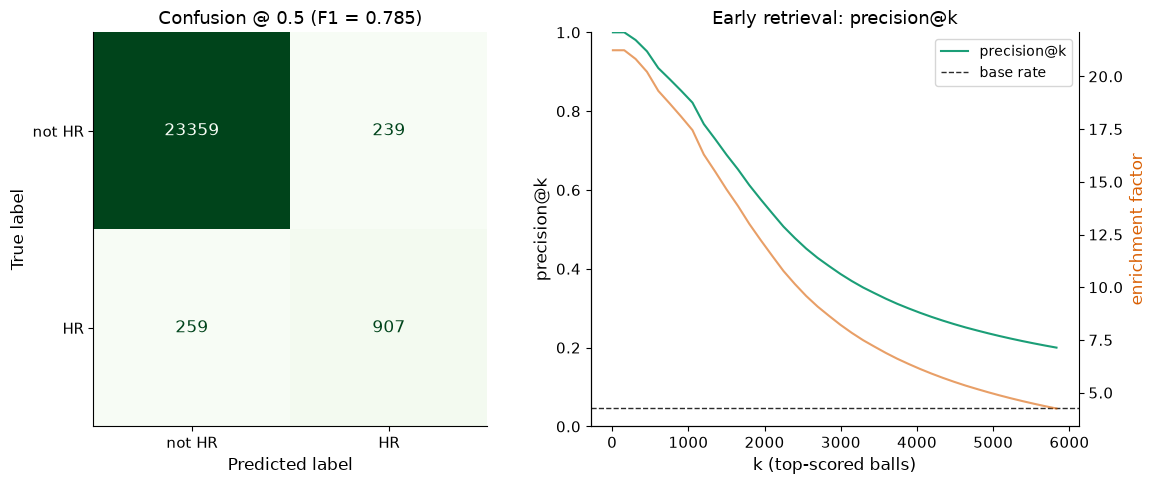

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
viz.plot_confusion(y_test, y_score, axes[0], pos_label="HR")
viz.plot_precision_at_k(y_test, y_score, axes[1])
plt.tight_layout()
plt.show()

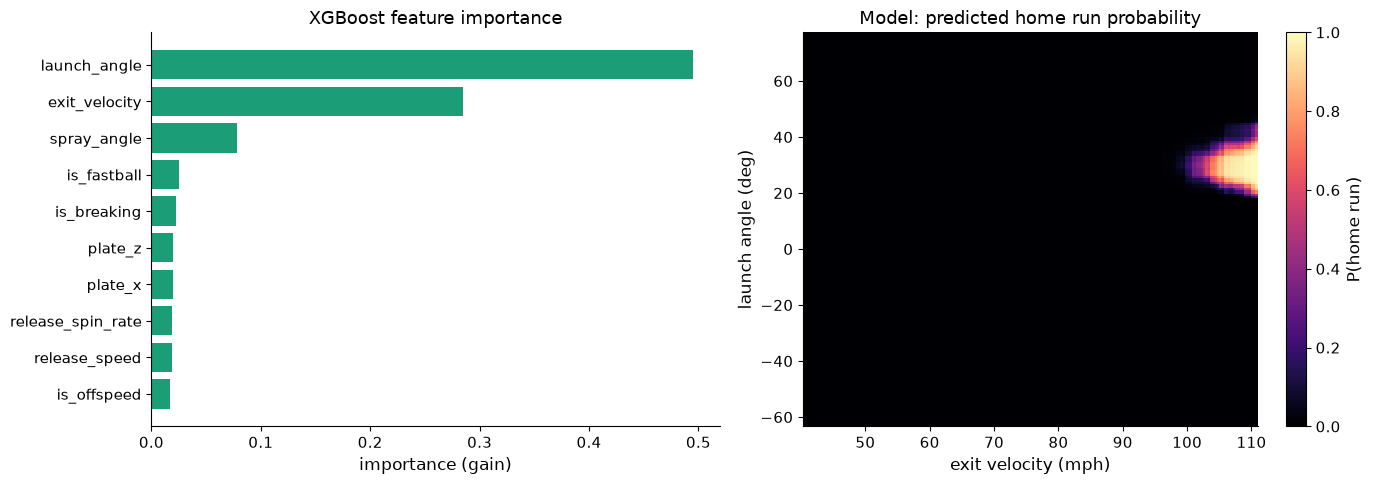

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
viz.plot_feature_importance(model, ds.feature_names, axes[0])
viz.plot_probability_heatmap(model, ds, axes[1], label="home run")
plt.tight_layout()
plt.show()

## 5. A harder target: triples

Triples (~0.6%) are rarer than home runs and **not** a tight cluster in this plane —
they depend on where the ball lands and on the runner's speed, neither of which is a
feature here. The same model is therefore a much weaker (and far more imbalanced)
problem: AUPRC drops sharply even though AUROC can still look respectable.

In [9]:
ds_tri = baseball.load_season(2023, target="triple")
tr, te = random_split(ds_tri, test_size=0.2)
m_tri = make_model("classification")
m_tri.fit(ds_tri.X[tr], ds_tri.y[tr])
y_tri = ds_tri.y[te]
s_tri = m_tri.predict_proba(ds_tri.X[te])[:, 1]
ev.compute_metrics(y_tri, s_tri)

{'auroc': 0.8772161847700614,
 'auprc': 0.030550745529546088,
 'f1': 0.0,
 'precision_at_k': 0.03,
 'enrichment_factor': 5.231830985915493}

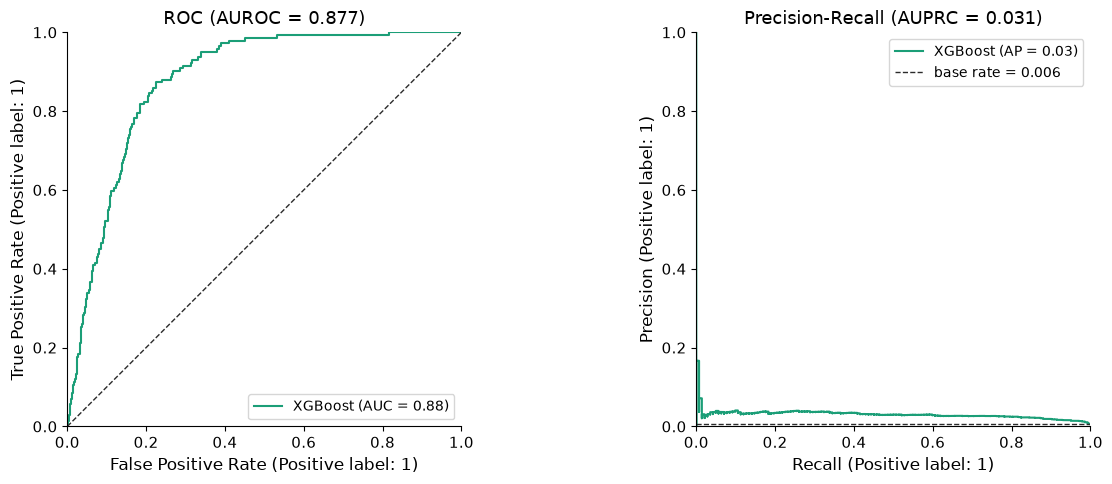

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
viz.plot_roc(y_tri, s_tri, axes[0])
viz.plot_pr(y_tri, s_tri, axes[1])
plt.tight_layout()
plt.show()

## 6. The hard split: train on 2023, test on 2024

Swapping the random within-season holdout for a **cross-season** test (train on all of
2023, evaluate on all of 2024) measures generalization under genuine distribution shift.
The table below contrasts the two regimes for both targets — AUPRC is the metric to watch
for these imbalanced problems.

In [11]:
rows = []
for target in ["home_run", "triple"]:
    d23 = baseball.load_season(2023, target=target)
    d24 = baseball.load_season(2024, target=target)
    splits = {"random": split_from_dataset(d23), "hard": cross_dataset_split(d23, d24)}
    for split_name, sp in splits.items():
        m = make_model("classification")
        m.fit(sp.train_ds.X, sp.train_ds.y)
        s = m.predict_proba(sp.X_test)[:, 1]
        met = ev.compute_metrics(sp.y_test, s)
        rows.append(
            {
                "target": target,
                "split": split_name,
                **{k: round(v, 3) for k, v in met.items()},
            }
        )
pd.DataFrame(rows)

,target,split,auroc,auprc,f1,precision_at_k,enrichment_factor
0,home_run,random,0.992,0.871,0.785,1.00,21.238
1,home_run,hard,0.993,0.870,0.781,0.99,22.661
2,triple,random,0.877,0.031,0.000,0.03,5.232
3,triple,hard,0.873,0.032,0.000,0.06,10.680


## 7. Negative control: how far does one feature get you?

For each feature we build a trivial "model" that scores examples by that one feature,
oriented by the sign of its correlation with the label, and evaluate it on the same
metric panel as the full model. If every single-feature control sits near chance while
the model does not, the model is capturing genuine multivariate structure.

For **triples** this is stark: no single feature separates the classes (launch angle's
correlation is ≈0 because triples sit at a *mid* launch angle — a non-monotonic
relationship a linear control cannot see), so the controls hug AUROC 0.5.

In [12]:
def full_factory(**kw):
    return make_model("classification", **kw)


nc = []
for target in ["home_run", "triple"]:
    d23 = baseball.load_season(2023, target=target)
    d24 = baseball.load_season(2024, target=target)
    splits = {"random": split_from_dataset(d23), "hard": cross_dataset_split(d23, d24)}
    for split_name, sp in splits.items():
        nc.append(
            run_negative_control(
                d23,
                full_factory,
                lambda feature_index: full_factory(
                    kind="correlation", feature_index=feature_index
                ),
                split=sp,
            ).assign(target=target, split=split_name)
        )
nc = pd.concat(nc, ignore_index=True)
nc[nc.target == "triple"].round(3)

,model,feature,corr,n_train,auroc,auprc,f1,precision_at_k,enrichment_factor,target,split
22,correlation,exit_velocity,0.055,99056,0.714,0.010,0.018,0.01,1.744,triple,random
23,correlation,launch_angle,0.018,99056,0.567,0.006,0.017,0.00,0.000,triple,random
24,correlation,spray_angle,-0.000,99056,0.525,0.007,0.013,0.00,0.000,triple,random
25,correlation,plate_x,0.017,99056,0.583,0.007,0.014,0.00,0.000,triple,random
26,correlation,plate_z,0.005,99056,0.482,0.005,0.010,0.00,0.000,triple,random
27,correlation,release_speed,0.009,99056,0.473,0.005,0.011,0.00,0.000,triple,random
28,correlation,release_spin_rate,-0.004,99056,0.524,0.006,0.012,0.00,0.000,triple,random
29,correlation,is_fastball,0.006,99056,0.495,0.006,0.011,0.00,0.000,triple,random
30,correlation,is_breaking,-0.007,99056,0.489,0.006,0.011,0.00,0.000,triple,random
31,correlation,is_offspeed,0.001,99056,0.494,0.006,0.010,0.00,0.000,triple,random


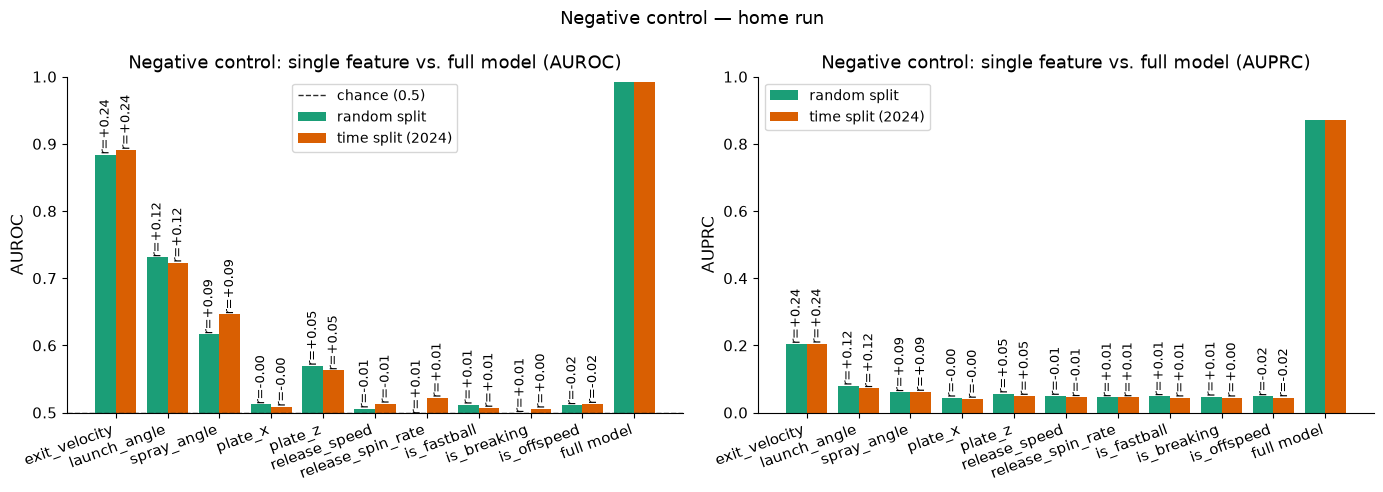

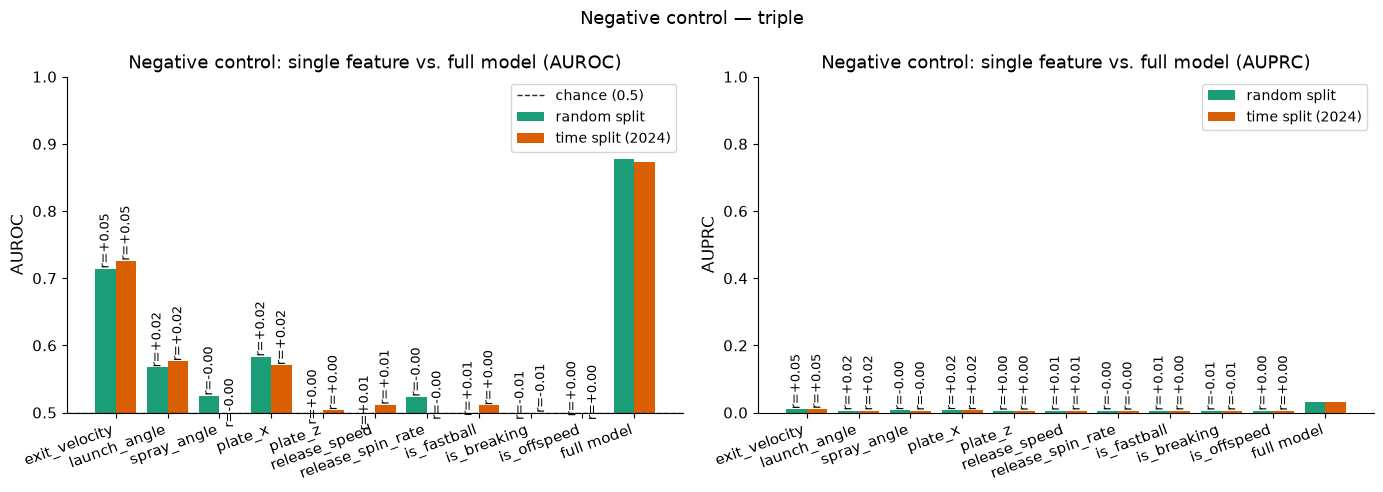

In [13]:
for target in ["home_run", "triple"]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    rviz.plot_negative_control(nc[nc.target == target], "auroc", axes[0])
    rviz.plot_negative_control(nc[nc.target == target], "auprc", axes[1])
    fig.suptitle(f"Negative control — {viz.target_label(target)}", fontsize=13)
    plt.tight_layout()
    plt.show()